# AnimalCLAP species study

This notebook evaluates AnimalCLAP species ranking on WildGuard's labeled wildlife recordings. Files are processed in deterministic 10-second windows with a 5-second hop. Similarity scores are rankings, not calibrated probabilities.

In [1]:
from pathlib import Path
import json
import os
import subprocess
import pandas as pd
import matplotlib.pyplot as plt

repo = Path.cwd()
if repo.name == 'notebooks':
    repo = repo.parent
manifest = repo / 'data/datasets/audioSet/Voicedata/data.csv'
output = repo / 'notebooks/results/animalclap_species_predictions.json'
output.parent.mkdir(parents=True, exist_ok=True)

In [2]:
if not output.exists():
    env = os.environ.copy()
    env['HF_HUB_CACHE'] = str(repo / 'storage/models/animalclap/huggingface/hub')
    command = [
        str(repo / 'model_services/audio/animalclap/.venv/bin/python'),
        str(repo / 'model_services/audio/animalclap/infer_species.py'),
        str(manifest), str(output),
    ]
    subprocess.run(command, cwd=repo, env=env, check=True)
else:
    print(f'Reusing {output}')

Reusing /home/vivek/Documents/Vivek-projects/WildGuard/notebooks/results/animalclap_species_predictions.json


In [3]:
payload = json.loads(output.read_text())
files = pd.DataFrame(payload['files'])
accuracy = files['correct'].mean()
print(f"Top-1 file accuracy: {accuracy:.1%} ({files['correct'].sum()}/{len(files)})")
files[['audio_file', 'expected_species', 'predicted_species', 'correct']]

Top-1 file accuracy: 35.7% (5/14)


,audio_file,expected_species,predicted_species,correct
0,coyote-verified.ogg,coyote,coyote,True
1,nri-CoyotesMOJA.mp3,coyote,coyote,True
2,nri-CoyotesChaseGRSA.mp3,coyote,coyote,True
3,nri-WolfDENA.mp3,wolf,coyote,False
4,wolf.ogg,wolf,coyote,False
5,nri-ElkBuglingGRSA.mp3,elk,coyote,False
6,Mountain Lion screaming!!!.mp3,mountain_lion,coyote,False
7,Mountain Lions Vocalizing!.mp3,mountain_lion,mountain_lion,True
8,yell-YELLgrizzlyA20160624SM3031431.mp3,grizzly_bear,grizzly_bear,True
9,yell-YELLgrizzlyB20160624SM3031431.mp3,grizzly_bear,wolf,False


In [4]:
class_summary = (files.groupby('expected_species')['correct']
                 .agg(['count', 'sum', 'mean'])
                 .rename(columns={'sum': 'correct', 'mean': 'top1_accuracy'}))
class_summary

,count,correct,top1_accuracy
expected_species,,,
coyote,3,3,1.000000
elk,1,0,0.000000
grizzly_bear,6,1,0.166667
mountain_lion,2,1,0.500000
wolf,2,0,0.000000


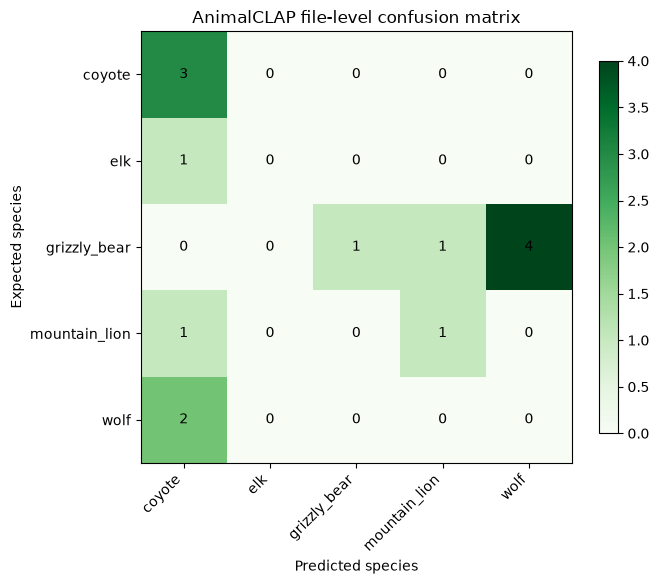

In [5]:
labels = payload['candidate_species']
matrix = pd.crosstab(files['expected_species'], files['predicted_species']).reindex(index=labels, columns=labels, fill_value=0)
fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(matrix.values, cmap='Greens')
ax.set_xticks(range(len(labels)), labels, rotation=45, ha='right')
ax.set_yticks(range(len(labels)), labels)
ax.set(xlabel='Predicted species', ylabel='Expected species', title='AnimalCLAP file-level confusion matrix')
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, matrix.iloc[i, j], ha='center', va='center')
fig.colorbar(image, ax=ax, shrink=0.8)
plt.tight_layout()
plt.savefig(repo / 'notebooks/results/animalclap_confusion_matrix.png', dpi=160, bbox_inches='tight')
plt.show()

In [6]:
window_rows = []
for file_result in payload['files']:
    for window in file_result['windows']:
        window_rows.append({
            'audio_file': file_result['audio_file'],
            'expected_species': file_result['expected_species'],
            **{k: window[k] for k in ('start_s', 'end_s', 'predicted_species')},
        })
windows = pd.DataFrame(window_rows)
windows['correct'] = windows['expected_species'] == windows['predicted_species']
print(f"Window accuracy: {windows['correct'].mean():.1%} across {len(windows)} windows")
windows

Window accuracy: 19.8% across 106 windows


,audio_file,expected_species,start_s,end_s,predicted_species,correct
0,coyote-verified.ogg,coyote,0.0,10.000,coyote,True
1,coyote-verified.ogg,coyote,5.0,15.000,coyote,True
2,coyote-verified.ogg,coyote,10.0,20.000,coyote,True
3,coyote-verified.ogg,coyote,15.0,25.000,coyote,True
4,coyote-verified.ogg,coyote,20.0,30.000,coyote,True
...,...,...,...,...,...,...
101,yell-YELLgrizzlyC20160626SM303143.mp3,grizzly_bear,30.0,40.000,wolf,False
102,yell-YELLgrizzlyC20160626SM303143.mp3,grizzly_bear,35.0,45.000,wolf,False
103,yell-YELLgrizzlyC20160626SM303143.mp3,grizzly_bear,40.0,50.000,wolf,False
104,yell-YELLgrizzlyC20160626SM303143.mp3,grizzly_bear,45.0,54.048,wolf,False


## Interpretation

This positive-only set measures identification among the five supplied species. It does not test whether AnimalCLAP can reject traffic, speech, wind, music, dogs, or silence. Add negative controls before setting an alert threshold or treating similarity as confidence.